# 03 Exploratory analysis

Input: `data/processed/model_table.csv` (notebook 04). The figures come from `src/plots.py` and are saved in `figures/`. Nothing here is used to fit the model, it only describes the data before modelling.

In [1]:
import sys
from pathlib import Path

# find the repo root (the folder that contains src/) wherever the notebook is started from
cwd = Path.cwd()
root = next(p for p in [cwd, cwd / "AdvanceData", *cwd.parents] if (p / "src").is_dir())
sys.path.insert(0, str(root / "src"))

import modeling
import plots

In [2]:
data = modeling.load_model_table()
print(data.shape, "rows;", data["race_id"].nunique(), "races;", data["year"].min(), "-", data["year"].max())
print("races with exactly one winner:", (data.groupby("race_id")["win"].sum() == 1).all())
data.columns.tolist()

(5545, 16) rows; 272 races; 2014 - 2026
races with exactly one winner: True


['year',
 'round',
 'driver_id',
 'constructor_id',
 'constructor_name',
 'grid',
 'position_order',
 'points',
 'race_id',
 'team',
 'team_pace3',
 'win',
 'driver_wins_before',
 'driver_team_wins_before',
 'driver_races_before',
 'driver_form3']

## 1. Who wins

Each race has exactly one winner, so the target is rare: about 1 driver in 20 wins. A handful of teams take most of the wins.

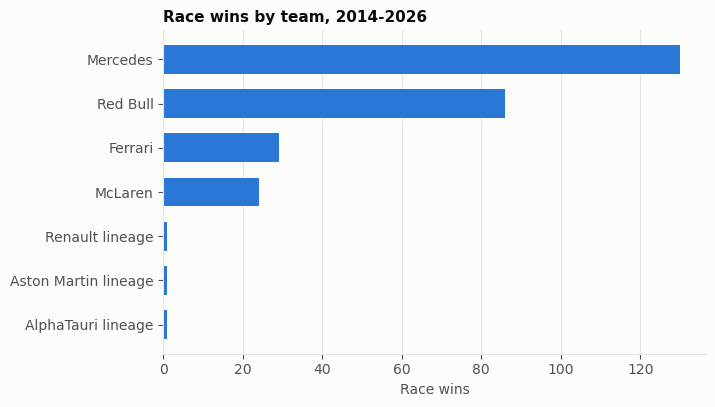

In [3]:
fig = plots.plot_winners_by_team(data)
plots.save_figure(fig, "winners_by_team.png")

*Figure.* Number of race wins of the ten most successful teams (teams that changed name are counted together, for example Force India, Racing Point and Aston Martin).

## 2. Starting position and the chance of winning

The grid is the strongest single predictor. The figure shows how often a start from each position ends in a win, before and after 2021.

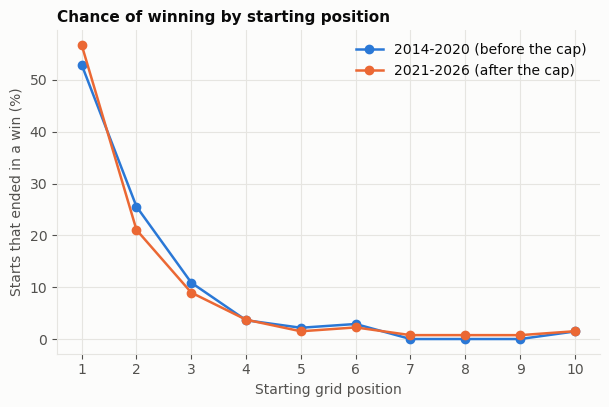

In [4]:
fig = plots.plot_grid_vs_win_rate(data)
plots.save_figure(fig, "grid_vs_win_rate.png")

*Figure.* Share of starts that ended in a win, by starting position (positions 1 to 10), for 2014-2020 and for 2021 onwards. The two lines are raw frequencies with no model and no intervals, and the number of races is small (about 20 per season), so differences between them can be noise.

## 3. How fast the strong teams are

`team_pace3` is the average gap to the fastest team (in percent of lap time) over the team's previous three races. It is the car variable of the model.

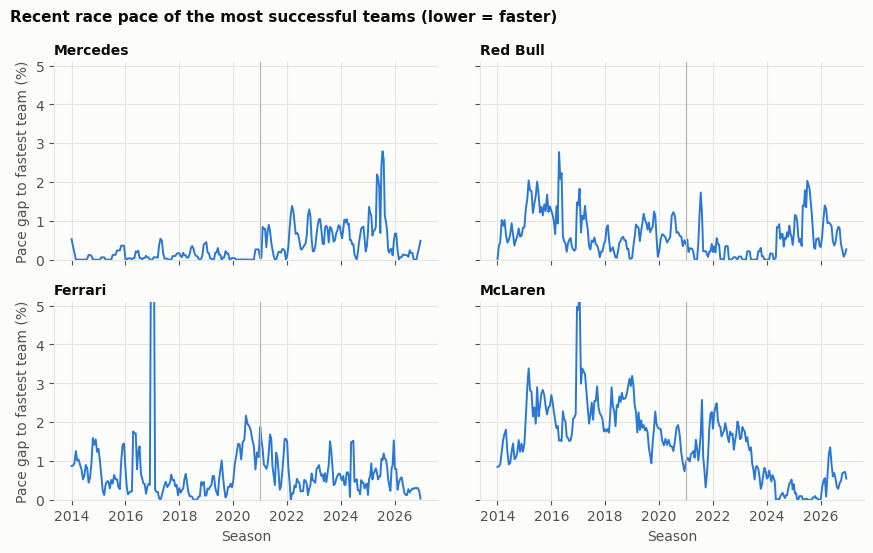

In [5]:
fig = plots.plot_team_pace_over_time(data)
plots.save_figure(fig, "team_pace_over_time.png")

*Figure.* Recent pace gap of the four teams with the most wins, race by race. Lower is faster; 0 means the team was the fastest. The grey vertical line marks 2021. Values at the start of a team's history are based on fewer than three previous races.

## Driver performance over time

Race wins per season of the six drivers with most wins in the data. Wins are counted from the results of each race, so this figure describes what happened and is not used as a predictor.

year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Hamilton,11,10,10,9,11,11,11,8,0,0,2,0,1
Max Verstappen,0,0,1,2,2,3,2,10,15,19,9,8,3
Rosberg,5,6,9,0,0,0,0,0,0,0,0,0,0
Norris,0,0,0,0,0,0,0,0,0,0,4,7,3
Vettel,0,3,0,5,5,1,0,0,0,0,0,0,0
Bottas,0,0,0,3,0,4,2,1,0,0,0,0,0


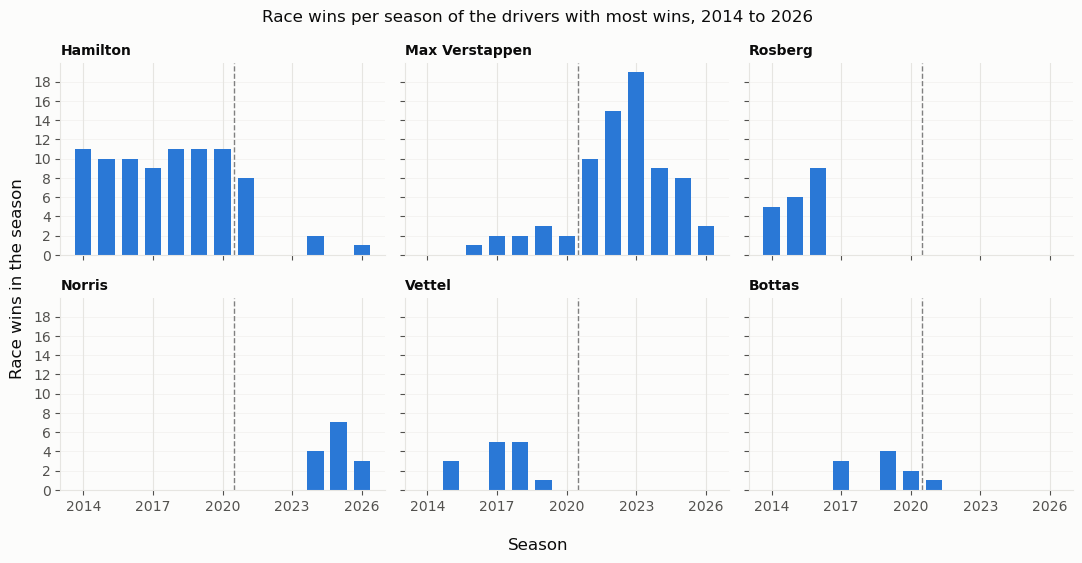

In [6]:
import driver_performance
import modeling

data = modeling.load_model_table()
driver_wins = driver_performance.wins_by_driver_season(data)
display(driver_wins)
plots.save_table(driver_wins, "driver_wins_by_season.csv")

fig = plots.plot_driver_wins_by_season(driver_wins)
plots.save_figure(fig, "driver_wins_by_season.png")

*Figure.* Number of races won in each season by the six drivers with most wins from 2014 to 2026. Each panel is one driver, and all panels share the same axes. The grey dashed line marks the first season with the cost cap.